# NB12: Operator Splitting & Adaptive Time-Stepping

This notebook demonstrates two fundamental numerical techniques used by the
RELIC simulator to integrate coupled biogeochemical ODEs:

1. **Operator Splitting** (Lie & Strang schemes) for decomposing coupled systems
2. **Adaptive Time-Stepping** with an I-controller-style step-size heuristic driven by committed fast-group state changes

**References:**
- Strang (1968), SIAM J. Numer. Anal. 5(3), 506--517
- Hairer & Wanner (1996), Solving Ordinary Differential Equations II
- McLachlan & Quispel (2002), Acta Numerica 11, 341--434
- Sportisse (2000), J. Comput. Phys. 161(1), 140--168

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Inspect operator splitting and adaptive timestep control through actual RELIC hydrology functors.
- Quantify order sensitivity, a full-step versus two-half-step comparison (a notebook diagnostic, not the RELIC controller), and cross-group read governance (lag warnings and `lagged` acknowledgement) with real simulator internals.
- Interpret timestep diagnostics without relying on notebook-defined toy ODEs.


In [1]:
import io
import logging
import math
import os
import sys
import warnings
from pathlib import Path

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'

warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')
warnings.filterwarnings('ignore', message='Source and target grids have identical cell counts.*')


def locate_project_root() -> Path:
    start = Path.cwd().resolve()
    fallback_paths = [Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    for candidate in [start] + list(start.parents) + fallback_paths:
        if (candidate / 'relic').exists() and (candidate / 'docs').exists():
            return candidate
    raise RuntimeError(f'Unable to locate RELIC project root from execution directory: {start}')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch
from relic.core.simulator import RELICSimulator
from relic.core.simulator.execution_loop import _compute_error_norm, _execute_fast_group, compute_splitting_sensitivity
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture

logging.getLogger('relic.coupling.scales.spatial.base_regridder').setLevel(logging.ERROR)


def tensor_scalar(value: object) -> float:
    tensor = torch.as_tensor(value).detach().reshape(-1)
    return float(tensor.to(dtype=torch.float64).cpu().tolist()[0])


def make_hydrology_state(
    soil_moisture: float = 0.34,
    precipitation_flux: float = 0.0,
    evapotranspiration_flux: float = 6.0e-05,
    net_radiation: float = 140.0,
    air_temperature: float = 291.15,
    wind_speed: float = 2.0,
    atmospheric_pressure: float = 101325.0,
    relative_humidity: float = 0.70,
    vapor_pressure_deficit: float = 900.0,
    surface_resistance: float = 110.0,
    canopy_conductance: float = 0.01,
    aerodynamic_resistance: float = 50.0,
) -> dict[str, torch.Tensor]:
    # PenmanMonteithET reads relative_humidity when it is present (vapor_pressure_deficit only
    # when it is absent) and, with canopy_resistance_source 'state', surface_resistance when it
    # is present (1 / canopy_conductance only when it is absent).
    return {
        'soil_moisture': torch.tensor(soil_moisture, dtype=torch.float32),
        'precipitation_flux': torch.tensor(precipitation_flux, dtype=torch.float32),
        'evapotranspiration_flux': torch.tensor(evapotranspiration_flux, dtype=torch.float32),
        'net_radiation': torch.tensor(net_radiation, dtype=torch.float32),
        'air_temperature': torch.tensor(air_temperature, dtype=torch.float32),
        'wind_speed': torch.tensor(wind_speed, dtype=torch.float32),
        'atmospheric_pressure': torch.tensor(atmospheric_pressure, dtype=torch.float32),
        'relative_humidity': torch.tensor(relative_humidity, dtype=torch.float32),
        'vapor_pressure_deficit': torch.tensor(vapor_pressure_deficit, dtype=torch.float32),
        'surface_resistance': torch.tensor(surface_resistance, dtype=torch.float32),
        'canopy_conductance': torch.tensor(canopy_conductance, dtype=torch.float32),
        'aerodynamic_resistance': torch.tensor(aerodynamic_resistance, dtype=torch.float32),
    }


def build_hydrology_simulator(
    splitting_mode: str = 'lie',
    adaptive_enabled: bool = False,
    time_step: float = 1800.0,
    initial_state: dict[str, torch.Tensor] | None = None,
    adaptive_overrides: dict[str, object] | None = None,
    bucket_execution_group: str = 'fast',
) -> RELICSimulator:
    config: dict[str, object] = {
        'time_step': float(time_step),
        'splitting_mode': str(splitting_mode),
        'enable_auto_scale': True,
        'conservation_checks': False,
        'device': 'cpu',
        'checkpoint_frequency': 1.0e30,
        'adaptive_dt_enabled': bool(adaptive_enabled),
        'adaptive_dt_min': 300.0,
        'adaptive_dt_max': float(time_step),
        'adaptive_atol': 1.0e-7,
        'adaptive_rtol': 5.0e-4,
        'adaptive_monitor_vars': ['soil_moisture', 'drainage_flux'],
    }
    if adaptive_overrides:
        config.update(adaptive_overrides)
    simulator = RELICSimulator(config)
    simulator.initialize_state(initial_state or make_hydrology_state())
    # canopy_resistance_source is a required PenmanMonteithET setting: 'state' takes the canopy
    # resistance r_s from the state; 'fao56_reference_surface' would use the FAO-56 reference
    # grass value (hydrosphere.physical.reference_surface_resistance).
    penman_functor = PenmanMonteithET(
        name='penman_monteith_et', config={'canopy_resistance_source': 'state'}
    )
    bucket_functor = BucketSoilMoisture(name='bucket_soil_moisture')
    # This open-system sequencing probe keeps the scientific metadata unchanged.
    simulator.register_functor(penman_functor, execution_group='fast')
    simulator.register_functor(bucket_functor, execution_group=bucket_execution_group)
    simulator._compute_group_execution_orders()
    return simulator


def hydrology_forcing_at_hour(hour: float) -> dict[str, torch.Tensor]:
    phase = 2.0 * math.pi * (hour - 6.0) / 24.0
    net_radiation = 120.0 + 220.0 * max(math.sin(phase), 0.0)
    air_temperature = 289.15 + 8.0 * math.sin(phase)
    vapor_pressure_deficit = 700.0 + 1600.0 * max(math.sin(phase), 0.0)
    relative_humidity = min(0.90, max(0.35, 1.0 - vapor_pressure_deficit / 4000.0))
    if 0.75 <= hour < 1.25:
        precipitation_flux = 0.0015
    elif 1.25 <= hour < 1.75:
        precipitation_flux = 0.0028
    elif 1.75 <= hour < 2.0:
        precipitation_flux = 0.0012
    else:
        precipitation_flux = 0.0
    return {
        'precipitation_flux': torch.tensor(precipitation_flux, dtype=torch.float32),
        'net_radiation': torch.tensor(net_radiation, dtype=torch.float32),
        'air_temperature': torch.tensor(air_temperature, dtype=torch.float32),
        'vapor_pressure_deficit': torch.tensor(vapor_pressure_deficit, dtype=torch.float32),
        'relative_humidity': torch.tensor(relative_humidity, dtype=torch.float32),
    }


def run_hydrology_sequence(
    adaptive_enabled: bool,
    end_time_hours: float = 3.0,
    time_step: float = 3600.0,
    adaptive_overrides: dict[str, object] | None = None,
) -> tuple[RELICSimulator, list[dict[str, float]]]:
    simulator = build_hydrology_simulator(
        adaptive_enabled=adaptive_enabled,
        time_step=time_step,
        adaptive_overrides=adaptive_overrides,
    )
    records: list[dict[str, float]] = []
    end_time_seconds = end_time_hours * 3600.0
    while simulator.current_time < end_time_seconds - 1.0e-9:
        dt_in = simulator.time_step if (not adaptive_enabled or not records) else simulator._adaptive_next_dt
        forcing = hydrology_forcing_at_hour(simulator.current_time / 3600.0)
        simulator.state_manager.set_state(forcing, validate=False)
        previous_time = simulator.current_time
        simulator.step(dt=min(dt_in, end_time_seconds - simulator.current_time))
        current_state = simulator._get_current_state()
        records.append({
            'time_hours': simulator.current_time / 3600.0,
            'effective_dt_seconds': simulator.current_time - previous_time,
            'soil_moisture': tensor_scalar(current_state['soil_moisture']),
            'evapotranspiration_flux': tensor_scalar(current_state['evapotranspiration_flux']),
            'drainage_flux': tensor_scalar(current_state['drainage_flux']),
            'precipitation_flux': tensor_scalar(forcing['precipitation_flux']),
        })
    return simulator, records


def evaluate_error_norm(state: dict[str, torch.Tensor], time_step: float, adaptive_overrides: dict[str, object] | None = None) -> float:
    simulator = build_hydrology_simulator(
        adaptive_enabled=True,
        time_step=time_step,
        initial_state=state,
        adaptive_overrides=adaptive_overrides,
    )
    simulator._step_update_sources = {}
    simulator._step_functor_increments = {}
    simulator._step_provenance_detail = {}
    state_before = simulator._get_current_state()
    # Group execution reads providers from the committed provider view that
    # step_simulation freezes for one admitted reader; the probe admits the
    # same reader token and releases it afterwards (registration owner).
    reader_token = simulator.acquire_provider_view()
    simulator._active_step_view = reader_token.view
    try:
        fast_updates = _execute_fast_group(simulator, time_step)
        return float(_compute_error_norm(simulator, state_before, fast_updates))
    finally:
        simulator._active_step_view = None
        reader_token.release()


def one_step_adaptive_response(
    state: dict[str, torch.Tensor],
    time_step: float,
    adaptive_overrides: dict[str, object] | None = None,
) -> dict[str, float]:
    simulator = build_hydrology_simulator(
        adaptive_enabled=True,
        time_step=time_step,
        initial_state=state,
        adaptive_overrides=adaptive_overrides,
    )
    simulator.step()
    current_state = simulator._get_current_state()
    return {
        'effective_dt_seconds': simulator.current_time,
        'suggested_next_dt_seconds': simulator._adaptive_next_dt,
        'soil_moisture': tensor_scalar(current_state['soil_moisture']),
        'evapotranspiration_flux': tensor_scalar(current_state['evapotranspiration_flux']),
    }


def richardson_comparison(state: dict[str, torch.Tensor], dt: float) -> dict[str, float]:
    simulator_full = build_hydrology_simulator(adaptive_enabled=False, time_step=dt, initial_state=state)
    simulator_full.step(dt=dt)
    state_full = simulator_full._get_current_state()

    simulator_half = build_hydrology_simulator(adaptive_enabled=False, time_step=dt * 0.5, initial_state=state)
    simulator_half.step(dt=dt * 0.5)
    simulator_half.step(dt=dt * 0.5)
    state_half = simulator_half._get_current_state()

    comparison = {}
    for variable_name in ['soil_moisture', 'evapotranspiration_flux', 'drainage_flux']:
        comparison[variable_name] = abs(
            tensor_scalar(state_half[variable_name]) - tensor_scalar(state_full[variable_name])
        )
    return comparison


def build_precipitation_event_simulator() -> RELICSimulator:
    simulator = build_hydrology_simulator(
        adaptive_enabled=False,
        time_step=3600.0,
        adaptive_overrides={'medium_interval_seconds': 1.0e9},
        bucket_execution_group='medium',
    )
    event_forcing = hydrology_forcing_at_hour(1.0)
    simulator.state_manager.set_state(event_forcing, validate=False)
    simulator.register_event_trigger(
        'medium',
        lambda state, time_seconds: float(torch.as_tensor(state['precipitation_flux']).reshape(-1)[0].item()) > 1.0e-6,
    )
    return simulator


print(f'Project root : {PROJECT_ROOT}')
print(f'PyTorch      : {torch.__version__}')
print('[OK] Imported actual RELIC simulator internals and scientific functors for NB12.')

Project root : <RELIC_ROOT>
PyTorch      : 2.13.0+cu130
[OK] Imported actual RELIC simulator internals and scientific functors for NB12.


## 1. Operator Splitting

Consider a coupled ODE system:

$$
\frac{dy}{dt} = f(y) = f_A(y) + f_B(y)
$$

where $f_A$ and $f_B$ represent different physical processes (e.g., photosynthesis
and soil decomposition). Direct integration of the coupled system is often expensive
or ill-conditioned. **Operator splitting** decomposes the problem into sub-problems
that are solved sequentially.

### 1.1 Lie (Sequential) Splitting

$$
\Phi_{\Delta t}^{\text{Lie}} = \Phi_B^{\Delta t} \circ \Phi_A^{\Delta t}
$$

Each operator advances the full time step $\Delta t$ in sequence.
This scheme is **first-order accurate**: $\mathcal{O}(\Delta t)$.

$$
y^{n+1} = \Phi_B^{\Delta t}\left(\Phi_A^{\Delta t}(y^n)\right) = y^n + \Delta t\,f(y^n) + \mathcal{O}(\Delta t^2)
$$

### 1.2 Strang (Symmetric) Splitting

$$
\Phi_{\Delta t}^{\text{Strang}} = \Phi_A^{\Delta t/2} \circ \Phi_B^{\Delta t} \circ \Phi_A^{\Delta t/2}
$$

The symmetric structure cancels the leading-order splitting error, giving
**second-order accuracy** $\mathcal{O}(\Delta t^2)$ when the sub-flows are exact (or the
sub-integrators satisfy the corresponding order and adjoint conditions) and smooth.

RELIC applies the palindrome to the whole fast-group plan order $F_1,\dots,F_n$:
$\Phi_{F_1}^{\Delta t/2}\circ\cdots\circ\Phi_{F_{n-1}}^{\Delta t/2}\circ\Phi_{F_n}^{\Delta t}\circ\Phi_{F_{n-1}}^{\Delta t/2}\circ\cdots\circ\Phi_{F_1}^{\Delta t/2}$
($2n-1$ sub-executions, each committed separately). Each sub-execution receives the interval
it covers: the first half-steps and the middle full step start at $t$, the second half-steps at
$t+\Delta t/2$. With exact smooth sub-flows the composition is therefore second order for any $n$,
also under non-autonomous forcing. The call order does not make numerical sub-integrators
symmetric: the effective order of one step is $q=\min(s,\min_i p_i)$ ($s=1$ for Lie, $s=2$ for
Strang), where $p_i$ is the `FunctorMetadata.sub_flow_accuracy` declared by fast Functor $i$
(`EXACT`, `ORDER_2`, `ORDER_1`; one `UNDECLARED` Functor makes $q$ "unverified").
`RELICSimulator.get_splitting_order_report()` returns $q$. With first-order sub-integrators such
as explicit Euler the step stays first order. Medium and slow groups are not part of this
composition.

### 1.3 Splitting Error and Commutativity

The splitting error depends on **commutators** of $f_A$ and $f_B$. For linear operators
with exact sub-flows $e^{\Delta t f_A}$ and $e^{\Delta t f_B}$ (matrix-product convention: the
operator applied later stands on the left; $f_A$ is applied first in Lie and on the half
steps in Strang), the leading term of $\log\Phi_{\Delta t} - \Delta t\,(f_A + f_B)$ is:

$$
\epsilon_{\text{split}} = \frac{\Delta t^2}{2} [f_B, f_A] + \mathcal{O}(\Delta t^3)
\qquad \text{(Lie)}
$$

$$
\epsilon_{\text{split}} = \frac{\Delta t^3}{24}\left(2[f_B,[f_B,f_A]] - [f_A,[f_A,f_B]]\right) + \mathcal{O}(\Delta t^5)
\qquad \text{(Strang)}
$$

For nonlinear vector fields, fix the Lie-bracket sign convention first; under the
vector-field (Lie derivative) convention the signs flip.

When the operators **commute** ($[f_A, f_B] = 0$) and the sub-flows are exact, splitting
introduces no error. In practice, biogeochemical processes rarely commute, so the order
sensitivity is worth measuring (next cells and Section 3.3).

### Demonstration: Evapotranspiration and Soil-Water Coupling

The demonstration uses two actual RELIC hydrology Functors in the fast group:

- $f_A$: `PenmanMonteithET` computes `evapotranspiration_flux` from the meteorological forcing
- $f_B$: `BucketSoilMoisture` updates `soil_moisture` from `precipitation_flux` and `evapotranspiration_flux`

Since $f_B$ reads the output of $f_A$, the result depends on the execution order. The next cell
measures this with `compute_splitting_sensitivity()` (one sequential pass per sampled permutation).

`PenmanMonteithET` is built with `canopy_resistance_source='state'`, a required setting: the canopy
resistance $r_s$ is the `surface_resistance` state (with `'fao56_reference_surface'` it would be the
FAO-56 reference grass value). Its soil heat flux uses the FAO-56 hourly fractions
($G = 0.1\,R_n$ for $R_n > 0$, $G = 0.5\,R_n$ otherwise), which hold for steps up to
`hydrosphere.physical.soil_heat_flux_hourly_max_step` (current configuration: 3600 s); an actual step
longer than that (a Strang half-step or a sub-step counts with its own length) raises `ValueError`.
Every step in this notebook is at most 3600 s; Section 3.2 shows what happens to a longer request.

In [2]:
# References:
# - Strang (1968), SIAM J. Numer. Anal.
# - Sportisse (2000), J. Comput. Phys.
# - RELIC execution_loop.compute_splitting_sensitivity()
# Mathematical expression:
# - m_sigma(v) = element mean of |v| after one sequential pass in order sigma
# - S(v) = std_sigma(m_sigma(v)) / mean_sigma(m_sigma(v))   (population standard deviation)
# - commutativity_violation = max_v S(v)
# Parameter meanings:
# - sigma: tested permutation of the actual fast functor order
# - dt_split: tested fast-process timestep
# - splitting_result: actual RELIC sensitivity report on hydrology state updates
# Units: dt_split [s]; m_sigma(v) in the units of v; S(v) dimensionless.
# Domain/constraints: every permutation starts from the same state; the simulator state is
#   restored after the scan.
# Sign convention: m_sigma(v) >= 0 and S(v) >= 0.

split_state = make_hydrology_state(
    soil_moisture=0.32,
    precipitation_flux=0.0018,
    evapotranspiration_flux=0.0,
    net_radiation=260.0,
    air_temperature=295.15,
    relative_humidity=0.65,
    vapor_pressure_deficit=1500.0,
    surface_resistance=120.0,
    aerodynamic_resistance=50.0,
)
dt_split = 1800.0
splitting_simulator = build_hydrology_simulator(
    splitting_mode='lie',
    adaptive_enabled=False,
    time_step=dt_split,
    initial_state=split_state,
)
splitting_result = compute_splitting_sensitivity(
    simulator=splitting_simulator,
    state=splitting_simulator._get_current_state(),
    dt=dt_split,
    group_order=splitting_simulator._order_fast,
    n_permutations=2,
)

positive_sensitivity = {
    name: value for name, value in splitting_result['per_variable_sensitivity'].items() if value > 0.0
}
selected_heatmap_variables = ['soil_moisture', 'drainage_flux', 'evapotranspiration_flux']
assert all(name in row for row in splitting_result['heatmap_data'] for name in selected_heatmap_variables)

print('=== Actual RELIC Splitting Sensitivity ===')
print(f"Fast order from simulator : {splitting_simulator._order_fast}")
print(f"Permutations tested       : {splitting_result['permutations_tested']}")
print(f"Commutativity violation   : {splitting_result['commutativity_violation']:.6e}")
print('Variables with non-zero sensitivity:')
for variable_name, value in sorted(positive_sensitivity.items(), key=lambda item: item[1], reverse=True):
    print(f'  {variable_name:24s} {value:.6e}')
print()
for row in splitting_result['heatmap_data']:
    print(f"Order {row['order']}")
    for variable_name in selected_heatmap_variables:
        if variable_name in row:
            print(f"  {variable_name:24s} {row[variable_name]:.6e}")
print('[OK] NB12 now measures splitting sensitivity from actual RELIC hydrology functors rather than a toy ODE.')

=== Actual RELIC Splitting Sensitivity ===
Fast order from simulator : ['penman_monteith_et', 'bucket_soil_moisture']
Permutations tested       : 2
Commutativity violation   : 5.264923e-04
Variables with non-zero sensitivity:
  drainage_flux            5.264923e-04
  soil_moisture            1.676475e-04

Order ['penman_monteith_et', 'bucket_soil_moisture']
  soil_moisture            3.164625e-01
  drainage_flux            3.702388e-03
  evapotranspiration_flux  6.285960e-05
Order ['bucket_soil_moisture', 'penman_monteith_et']
  soil_moisture            3.165687e-01
  drainage_flux            3.706289e-03
  evapotranspiration_flux  6.285960e-05
[OK] NB12 now measures splitting sensitivity from actual RELIC hydrology functors rather than a toy ODE.


## 2. RELIC Splitting Implementation

The canonical owner is `_execute_fast_group` in
`relic.core.simulator.execution_loop`. Every group call receives an explicit
`start_time` and commits once through StateManager. One
`GroupComposition(interval=step_dt)` is shared by all `2n-1` Strang
sub-executions of an attempt; a retry creates a new composition.

The composition retains dependency outputs, merged diagnostics, and boundary
rates. A consumer of `subprocess_outputs` sees a provider's latest earlier
sub-execution; each output retains its declared rate or amount semantics.

`merge_sequential_updates(..., coverage=h/H)` is the one merge rule:

- Plain diagnostics and `REPLACE` items keep the last value.
- `ACCUMULATE` amounts and plain state increments are summed.
- Unintegrated per-second `ACCUMULATE` rates are weighted by `h/H`:
  substeps form a time-weighted mean, same-interval Functors add, and two
  Strang half-steps form the mean of that process's two rates.

StateManager integrates a rate once over its real commit interval; a declared
boundary-rate aggregate exposes the current-composition sum of latest writer
contributions during execution, with no previous-step mean added. Provider
substeps expose their latest reduced rate; after the provider call its own
interval mean is visible and retained in dependency outputs. Only after the
composition completes is the full `h/H` mean stored. Each writer/substep is
reduced once; stage/final restatements add no second ledger entry. Stored diagnostics agree with the step return. The adaptive metric
uses committed state changes, not the merged payload's numeric magnitude.

```yaml
simulator:
  splitting_mode: "strang"   # or "lie" (default)
```


### Commutativity Violation Metric

RELIC quantifies the **commutativity violation** by testing multiple permutations
of the functor execution order and measuring the sensitivity:

$$
\text{sensitivity}_k = \frac{\text{std}\left(\\{y_k^{\sigma}\\}_{\sigma}\right)}{\text{mean}\left(|y_k^{\sigma}|\right)}
$$

$$
\text{commutativity\\_violation} = \max_k \text{sensitivity}_k
$$

This is implemented in `compute_splitting_sensitivity()` from
`relic.core.simulator.execution_loop`.

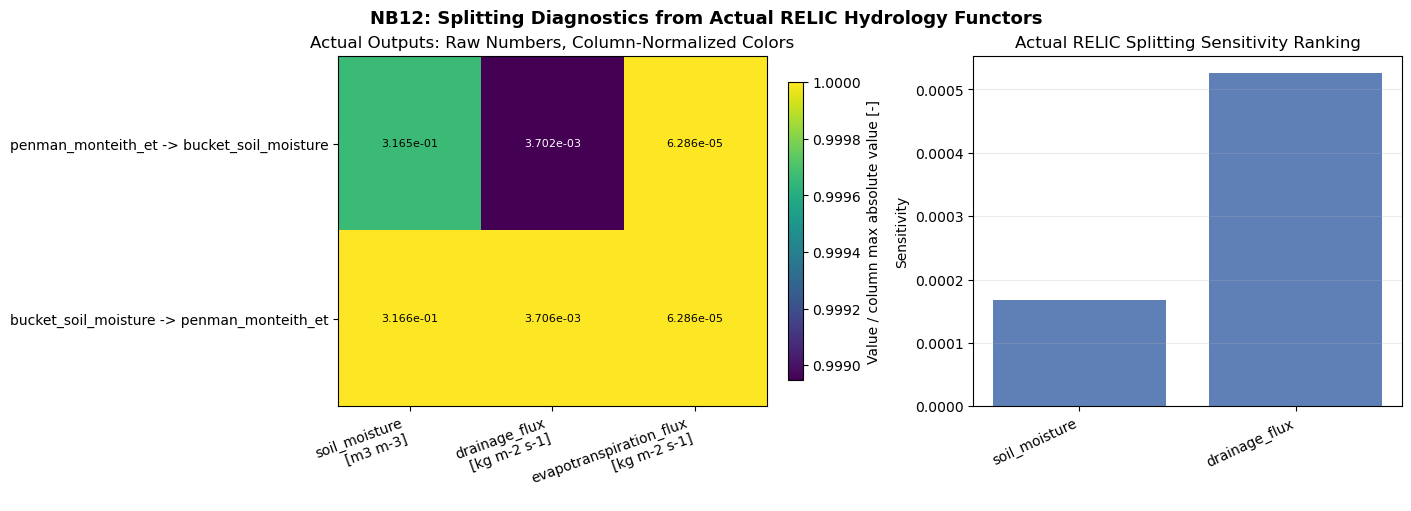

[OK] NB12 splitting visualization uses actual permutation outputs from compute_splitting_sensitivity().


In [3]:
from IPython.display import display
# References:
# - RELIC execution_loop.compute_splitting_sensitivity()
# - Strang (1968), SIAM J. Numer. Anal.
# Mathematical expression:
# - Delta_v(sigma_i, sigma_j) = result_sigma_i(v) - result_sigma_j(v)
# Parameter meanings:
# - heatmap_rows: permutation-specific actual RELIC outputs
# - selected_heatmap_variables: state variables emphasized in the visualization
# - positive_sensitivity: non-zero sensitivity metrics from the actual simulator
# Display only: colors use each value divided by its column maximum absolute value.
# Cell text retains actual values in the units shown under each column.

heatmap_rows = splitting_result['heatmap_data']
assert len(heatmap_rows) == 2, 'NB12 expects exactly two permutations for the two-functor hydrology example.'

heatmap_tensor = torch.tensor(
    [[float(row[variable_name]) for variable_name in selected_heatmap_variables] for row in heatmap_rows],
    dtype=torch.float64,
)
heatmap_display = heatmap_tensor.clone()
for column_idx in range(heatmap_display.shape[1]):
    column_abs_max = torch.max(torch.abs(heatmap_display[:, column_idx]))
    if column_abs_max > 0.0:
        heatmap_display[:, column_idx] = heatmap_display[:, column_idx] / column_abs_max

bar_variables = list(positive_sensitivity.keys())
bar_values = [positive_sensitivity[name] for name in bar_variables]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

ax = axes[0]
im = ax.imshow(heatmap_display.cpu().tolist(), cmap='viridis', aspect='auto', vmin=None, vmax=None)
for row_idx in range(heatmap_tensor.shape[0]):
    for column_idx in range(heatmap_tensor.shape[1]):
        ax.text(
            column_idx,
            row_idx,
            f"{heatmap_tensor[row_idx, column_idx].item():.3e}",
            ha='center',
            va='center',
            fontsize=8,
            color='black' if im.norm(float(heatmap_display[row_idx, column_idx])) > 0.55 else 'white',
        )
ax.set_title('Actual Outputs: Raw Numbers, Column-Normalized Colors')
ax.set_xticks(range(len(selected_heatmap_variables)))
display_units = {'soil_moisture': 'm3 m-3', 'drainage_flux': 'kg m-2 s-1', 'evapotranspiration_flux': 'kg m-2 s-1'}
ax.set_xticklabels([f'{name}\n[{display_units[name]}]' for name in selected_heatmap_variables], rotation=20, ha='right')
ax.set_yticks(range(len(heatmap_rows)))
ax.set_yticklabels([' -> '.join(row['order']) for row in heatmap_rows])
fig.colorbar(im, ax=ax, shrink=0.85, label='Value / column max absolute value [-]')

ax = axes[1]
ax.bar(range(len(bar_variables)), bar_values, color='#4C72B0', alpha=0.90)
ax.set_xticks(range(len(bar_variables)))
ax.set_xticklabels(bar_variables, rotation=25, ha='right')
ax.set_ylabel('Sensitivity')
ax.set_title('Actual RELIC Splitting Sensitivity Ranking')
ax.grid(True, axis='y', alpha=0.25)

plt.suptitle('NB12: Splitting Diagnostics from Actual RELIC Hydrology Functors', fontsize=13, fontweight='bold')
display(plt.gcf())
plt.close(plt.gcf())
print('[OK] NB12 splitting visualization uses actual permutation outputs from compute_splitting_sensitivity().')

## 3. Adaptive Time-Stepping

RELIC uses an **I-controller-style step-size heuristic** (after the elementary controller of
Hairer & Wanner 1996) driven by the magnitude of the committed fast-group state changes. It is enabled
by `adaptive_dt_enabled` and is not an error estimate.

### 3.1 Error Norm Computation

For each monitored state variable $y_k$, the tolerance-weighted metric is:

$$
\text{tol}_k = \text{atol} + \text{rtol} \cdot |y_k|
$$

$$
\mathcal{E} = \sqrt{\frac{1}{m} \sum_{k=1}^{m} \operatorname{mean}_{\text{elements}}\left(\frac{\delta_k}{\text{tol}_k}\right)^2}
$$

where $\delta_k=y'_k-y_k$ is the change StateManager actually committed to
monitored variable $k$. It includes real-interval rate integration, clipping,
and distributed reduction; the merged return identifies actual StateManager targets after the existing `delta_x` to `x` mapping. Targets are deduplicated before monitor filtering and pre/post-state lookup; SCM read aliases remain unwritable. The squared ratio is first averaged over tensor elements, and $|y_k|$ is the state
before the fast group; $m$ is the number of monitored variables (equal weight). Only fast-group
updates enter $\mathcal{E}$. Until 2026-09-23 the runtime used $v_k$ itself for REPLACE updates,
which gave $\mathcal{E} \approx 1/\text{rtol}$ whatever the step length.

### 3.2 I-Controller Step Size Selection

$$
\Delta t_{n+1} = \Delta t_n \cdot \min\left(5, \max\left(0.1, \frac{0.9}{\mathcal{E}^{0.5}}\right)\right)
$$

- If $\mathcal{E} > 1$ and $\Delta t > \Delta t_{\min}$: roll back the fast group and re-run it once with
  $\max(\Delta t\max(0.1,0.9/\sqrt{\mathcal E}),\Delta t_{\min})$, which is always shorter than the
  rejected attempt; the retry is accepted without a second check, and its $\Delta t$ becomes the
  next proposal
- If $\mathcal{E} > 1$ and $\Delta t \le \Delta t_{\min}$: no shorter retry exists; the attempt is
  accepted without rollback, a WARNING names $\mathcal E$ and $\Delta t_{\min}$, and the next
  proposal follows the accepted-step rule below
- If $\mathcal{E} \le 1$: accept; next $\Delta t$ from the formula above ($2\Delta t$ if $\mathcal E=0$),
  clipped to $[\Delta t_{\min},\Delta t_{\max}]$
- The factors (0.9, 0.1, 5, 2) are code constants and heuristic; they do not guarantee stability

In [4]:
# References:
# - Hairer and Wanner (1996), ODE II.
# - RELIC execution_loop._compute_error_norm()
# Mathematical expression:
# - tol_k = atol + rtol * |y_k|
# - E = sqrt((1/m) * sum_k mean_elements((delta_k / tol_k)^2))
# Parameter meanings:
# - adaptive_atol, adaptive_rtol: controller tolerances in the actual simulator
# - E: actual RELIC adaptive error norm for the selected monitored variables
# - delta_k: committed post-fast value minus pre-fast value, including rate integration.
# Units: State changes and atol use each variable's stored units; E and rtol are dimensionless.
# Domain/constraints: Numeric pre-step values of written monitored states; no diagnostic outputs.
# Sign convention: Positive delta_k increases the state; the squared metric ignores its sign.

error_norm_state = make_hydrology_state(
    soil_moisture=0.34,
    precipitation_flux=0.0015,
    evapotranspiration_flux=6.0e-05,
    net_radiation=220.0,
    air_temperature=294.15,
    relative_humidity=0.65,
    vapor_pressure_deficit=1400.0,
)
error_norm_settings = {
    'strict': {'adaptive_atol': 1.0e-7, 'adaptive_rtol': 5.0e-4},
    'relaxed': {'adaptive_atol': 1.0e-5, 'adaptive_rtol': 5.0e-2},
}
error_norm_summary = {}
for setting_name, overrides in error_norm_settings.items():
    error_norm_summary[setting_name] = evaluate_error_norm(
        state=error_norm_state,
        time_step=3600.0,
        adaptive_overrides=overrides,
    )

print('=== Actual RELIC Error Norms ===')
for setting_name, error_norm_value in error_norm_summary.items():
    decision = 'reject and shrink dt' if error_norm_value > 1.0 else 'accept current dt'
    print(f"{setting_name:8s} | E = {error_norm_value:.6f} | controller action: {decision}")
print('[OK] NB12 now evaluates the adaptive error norm by calling RELIC execution_loop internals on actual functor updates.')

=== Actual RELIC Error Norms ===
strict   | E = 64.991664 | controller action: reject and shrink dt
relaxed  | E = 0.649917 | controller action: accept current dt
[OK] NB12 now evaluates the adaptive error norm by calling RELIC execution_loop internals on actual functor updates.


In [5]:
# References:
# - RELIC execution_loop._execute_fast_with_adaptive_retry()
# - Hairer and Wanner (1996), ODE II.
# Mathematical expression:
# - dt_retry = max(dt * max(0.1, 0.9 / sqrt(E)), dt_min) < dt when E > 1 and dt > dt_min; the
#   retry is accepted without a second check and becomes the next proposal
# - E > 1 and dt <= dt_min: the attempt is accepted without rollback (WARNING); the next
#   proposal follows the accepted-step rule below
# - E <= 1: the step is accepted at dt; dt_next = dt * min(5, max(0.1, 0.9 / sqrt(E)))
#   (2 * dt if E == 0), clipped to [dt_min, dt_max]
# Parameter meanings:
# - effective_dt_seconds: accepted step after any internal retry [s]
# - suggested_next_dt_seconds: simulator._adaptive_next_dt after the completed step [s]

adaptive_sweep_state = make_hydrology_state(
    soil_moisture=0.34,
    precipitation_flux=0.0015,
    evapotranspiration_flux=6.0e-05,
    net_radiation=220.0,
    air_temperature=294.15,
    relative_humidity=0.65,
    vapor_pressure_deficit=1400.0,
)
adaptive_sweep_settings = {
    'strict': {'adaptive_atol': 1.0e-7, 'adaptive_rtol': 5.0e-4},
    'moderate': {'adaptive_atol': 1.0e-6, 'adaptive_rtol': 1.0e-2},
    'relaxed': {'adaptive_atol': 1.0e-5, 'adaptive_rtol': 5.0e-2},
}
adaptive_sweep_summary = {}
for setting_name, overrides in adaptive_sweep_settings.items():
    adaptive_sweep_summary[setting_name] = one_step_adaptive_response(
        state=adaptive_sweep_state,
        time_step=3600.0,
        adaptive_overrides=overrides,
    )

print('=== Actual Adaptive Retry Sweep ===')
print(f"{'Setting':>8s} {'Accepted dt [s]':>18s} {'Suggested next dt [s]':>23s} {'Soil moisture':>16s}")
print('-' * 72)
for setting_name, summary in adaptive_sweep_summary.items():
    print(
        f"{setting_name:>8s} {summary['effective_dt_seconds']:18.3f} "
        f"{summary['suggested_next_dt_seconds']:23.3f} {summary['soil_moisture']:16.6f}"
    )
# Documentation oracle (not a controller): each accepted dt and next proposal must equal the
# runtime rule applied to the error norm E of the same initial state (computed by
# _compute_error_norm()): one retry when E > 1 and dt > dt_min, acceptance at the requested
# dt otherwise.
sweep_probe = build_hydrology_simulator(adaptive_enabled=True, time_step=3600.0)
sweep_dt_min = sweep_probe._adaptive_dt_min
sweep_dt_max = sweep_probe._adaptive_dt_max
print('Oracle check against the documented runtime rule:')
for setting_name, overrides in adaptive_sweep_settings.items():
    error_norm_value = evaluate_error_norm(adaptive_sweep_state, 3600.0, overrides)
    if error_norm_value > 1.0 and 3600.0 > sweep_dt_min:
        rule_dt = max(3600.0 * max(0.1, 0.9 / math.sqrt(error_norm_value)), sweep_dt_min)
        rule_next_dt = rule_dt
        action = 'rejected, one retry'
    else:
        rule_dt = 3600.0
        growth = 2.0 if error_norm_value == 0.0 else min(5.0, max(0.1, 0.9 / math.sqrt(error_norm_value)))
        rule_next_dt = max(min(3600.0 * growth, sweep_dt_max), sweep_dt_min)
        action = 'accepted' if error_norm_value <= 1.0 else 'accepted at dt_min'
    summary = adaptive_sweep_summary[setting_name]
    assert abs(summary['effective_dt_seconds'] - rule_dt) <= 1.0e-6 * rule_dt
    assert abs(summary['suggested_next_dt_seconds'] - rule_next_dt) <= 1.0e-6 * rule_next_dt
    print(
        f"{setting_name:>8s} | E = {error_norm_value:10.4f} | {action:19s} | rule dt = {rule_dt:9.3f} s | "
        f"rule next dt = {rule_next_dt:9.3f} s | matches"
    )
print('[OK] NB12 adaptive control sweep now comes from actual simulator retries, not a hand-written I-controller toy function.')

=== Actual Adaptive Retry Sweep ===
 Setting    Accepted dt [s]   Suggested next dt [s]    Soil moisture
------------------------------------------------------------------------
  strict            401.898                 401.898         0.338838
moderate           1797.080                1797.080         0.334663
 relaxed           3600.000                3600.000         0.328945
Oracle check against the documented runtime rule:
  strict | E =    64.9917 | rejected, one retry | rule dt =   401.898 s | rule next dt =   401.898 s | matches


moderate | E =     3.2505 | rejected, one retry | rule dt =  1797.080 s | rule next dt =  1797.080 s | matches
 relaxed | E =     0.6499 | accepted            | rule dt =  3600.000 s | rule next dt =  3600.000 s | matches
[OK] NB12 adaptive control sweep now comes from actual simulator retries, not a hand-written I-controller toy function.


### Multi-Step Adaptive Simulation

We now simulate the coupled evapotranspiration/soil-water system over three hours using adaptive
time-stepping with the Lie composition of the fast group. The controller adjusts $\Delta t$ based
on the committed-state-change magnitude heuristic (not a local truncation error estimate). `run()` uses
the proposed next $\Delta t$; a direct `step(dt)` uses its argument, so the sequence below passes
the proposal explicitly.

In [6]:
# References:
# - RELICSimulator.step() and execution_loop.run_simulation()
# - Penman-Monteith ET and bucket soil-water balance in RELIC hydrosphere
# Mathematical expression:
# - soil_moisture_{n+1} = BucketSoilMoisture(soil_moisture_n, P_n, ET_n, dt_n)
# - ET_n = PenmanMonteithET(meteorology_n, dt_n)
# Parameter meanings:
# - adaptive_records: actual RELIC run with dt chosen from simulator._adaptive_next_dt
# - fixed_records: actual RELIC run with constant dt = 3600 s
# - effective_dt_seconds: accepted time increment after any internal adaptive retry
# - adaptive_retries: rejected attempts longer than dt_min that were rolled back and retried
# - adaptive_accepted_at_dt_min: attempts with E > 1 at or below dt_min accepted with a WARNING

adaptive_log_stream = io.StringIO()
adaptive_log_handler = logging.StreamHandler(adaptive_log_stream)
adaptive_logger = logging.getLogger('relic.core.simulator.execution_loop')
adaptive_previous_level = adaptive_logger.level
adaptive_logger.setLevel(logging.DEBUG)
adaptive_logger.addHandler(adaptive_log_handler)
try:
    adaptive_simulator, adaptive_records = run_hydrology_sequence(
        adaptive_enabled=True,
        end_time_hours=3.0,
        time_step=3600.0,
    )
finally:
    adaptive_logger.removeHandler(adaptive_log_handler)
    adaptive_logger.setLevel(adaptive_previous_level)
adaptive_log_lines = adaptive_log_stream.getvalue().splitlines()
adaptive_retries = sum('Adaptive step rejected' in line for line in adaptive_log_lines)
adaptive_accepted_at_dt_min = sum('Adaptive step accepted with Err' in line for line in adaptive_log_lines)
fixed_simulator, fixed_records = run_hydrology_sequence(
    adaptive_enabled=False,
    end_time_hours=3.0,
    time_step=3600.0,
)

adaptive_dt_values = [record['effective_dt_seconds'] for record in adaptive_records]
fixed_dt_values = [record['effective_dt_seconds'] for record in fixed_records]

print('=== Actual Multi-Step Hydrology Run ===')
print(f"Adaptive steps        : {len(adaptive_records)}")
print(f"Adaptive dt range [s] : ({min(adaptive_dt_values):.1f}, {max(adaptive_dt_values):.1f})")
print(f"Adaptive end time [s] : {adaptive_simulator.current_time:.1f}")
print(f"Adaptive retries      : {adaptive_retries} (rejected attempt longer than dt_min, rolled back)")
print(f"Accepted at dt_min    : {adaptive_accepted_at_dt_min} (E > 1 with attempt <= dt_min, WARNING)")
print(f"Fixed steps           : {len(fixed_records)}")
print(f"Fixed dt unique [s]   : {sorted(set(fixed_dt_values))}")
print(f"Adaptive final theta  : {adaptive_records[-1]['soil_moisture']:.6f}")
print(f"Fixed final theta     : {fixed_records[-1]['soil_moisture']:.6f}")
assert abs(adaptive_simulator.current_time - 3.0 * 3600.0) <= 1.0e-6
print('[OK] NB12 adaptive sequence now runs through actual RELIC fast-process steps with time-varying meteorological forcing.')

=== Actual Multi-Step Hydrology Run ===
Adaptive steps        : 36
Adaptive dt range [s] : (240.0, 360.0)
Adaptive end time [s] : 10800.0
Adaptive retries      : 2 (rejected attempt longer than dt_min, rolled back)
Accepted at dt_min    : 34 (E > 1 with attempt <= dt_min, WARNING)
Fixed steps           : 3
Fixed dt unique [s]   : [3600.0]
Adaptive final theta  : 0.308171
Fixed final theta     : 0.303109
[OK] NB12 adaptive sequence now runs through actual RELIC fast-process steps with time-varying meteorological forcing.


## 4. RELIC API Reference

### Key Functions of the Fast-Group Composition (`relic.core.simulator.execution_loop` unless noted)

| Function | Purpose |
|----------|---------|
| `_execute_fast_group()` | Apply Lie or Strang splitting to fast process group; every call passes `start_time` |
| `GroupComposition` (`execution_group`) | State shared by the sub-executions of one fast-group attempt: dependency outputs (`subprocess_outputs`), merged per-Functor diagnostics, per-writer stage boundary rates, and a private complete-interval rate accumulator finalized after successful composition |
| `merge_sequential_updates()` (`execution_group`) | Single merge rule for sub-steps, the Functors of a group call and the Strang sub-executions (plain diagnostic: last observation; REPLACE: last value; ACCUMULATE amounts and plain state increments: sum; unintegrated per-second ACCUMULATE rates: weighted by `h/H`) |
| `splitting_order_report()` | Effective order $q=\min(s,\min_i p_i)$ from `sub_flow_accuracy` (`RELICSimulator.get_splitting_order_report()`) |
| `_compute_error_norm()` | Tolerance-weighted RMS of the changes applied by the fast group (committed value minus pre-step value; control heuristic) |
| `_execute_fast_with_adaptive_retry()` | One rollback and a shorter retry when $\mathcal{E} > 1$ and $\Delta t > \Delta t_{\min}$; acceptance with a WARNING when $\mathcal{E} > 1$ and $\Delta t \le \Delta t_{\min}$; next-$\Delta t$ proposal otherwise |
| `compute_splitting_sensitivity()` | Measure commutativity violation across permutations |

### Configuration (YAML)

```yaml
simulator:
  splitting_mode: "strang"     # "lie" (default) or "strang"
  adaptive_dt_enabled: true
  adaptive_atol: 1.0e-6        # absolute tolerance
  adaptive_rtol: 1.0e-3        # relative tolerance
  adaptive_dt_min: 1.0         # min step [s]
  adaptive_dt_max: 36000.0     # max step [s]
  adaptive_monitor_vars:       # variables to monitor (null = all)
    - leaf_carbon
    - soil_carbon
```

### Step Size Evolution

The adaptive controller adjusts $\Delta t$ from the committed-state-change heuristic $\mathcal E$. Values
$\mathcal E < 0.81$ grow the next step; $\mathcal E>1$ causes one rollback and a shorter retry whose result is accepted
without a second check, unless the attempt is already at or below $\Delta t_{\min}$, in which case it is
accepted without rollback and a WARNING is logged.

In this example the monitored `soil_moisture` and `drainage_flux` updates are REPLACE updates, and
$\mathcal E$ measures their changes (committed value minus pre-step value), so it depends on the step
and the tolerances. Cell 12 gives $\mathcal E = 65.0$, $3.25$ and $0.65$ at 3600 s for
rtol $= 5\times10^{-4}$, $10^{-2}$ and $5\times10^{-2}$ (only the last accepts the 3600 s step), and cell 29
gives $\mathcal E = 17.2$, $35.7$, $55.4$ and $76.4$ for requested steps of 900, 1800, 2700 and 3600 s
(a request longer than 3600 s fails in `PenmanMonteithET` before $\mathcal E$ is computed).
The run below uses the strict tolerances (atol $=10^{-7}$, rtol $=5\times10^{-4}$), and every attempt
has $\mathcal E > 1$. The first two attempts are longer than $\Delta t_{\min}$ and are retried (3600 s is
cut to 360 s, the next proposal of 360 s to 300 s); the remaining 34 attempts are at or below
$\Delta t_{\min} = 300$ s and are accepted without rollback, each with a WARNING (cell 14 counts both).
The last step is shortened to 240 s, so the run ends at 10 800 s.

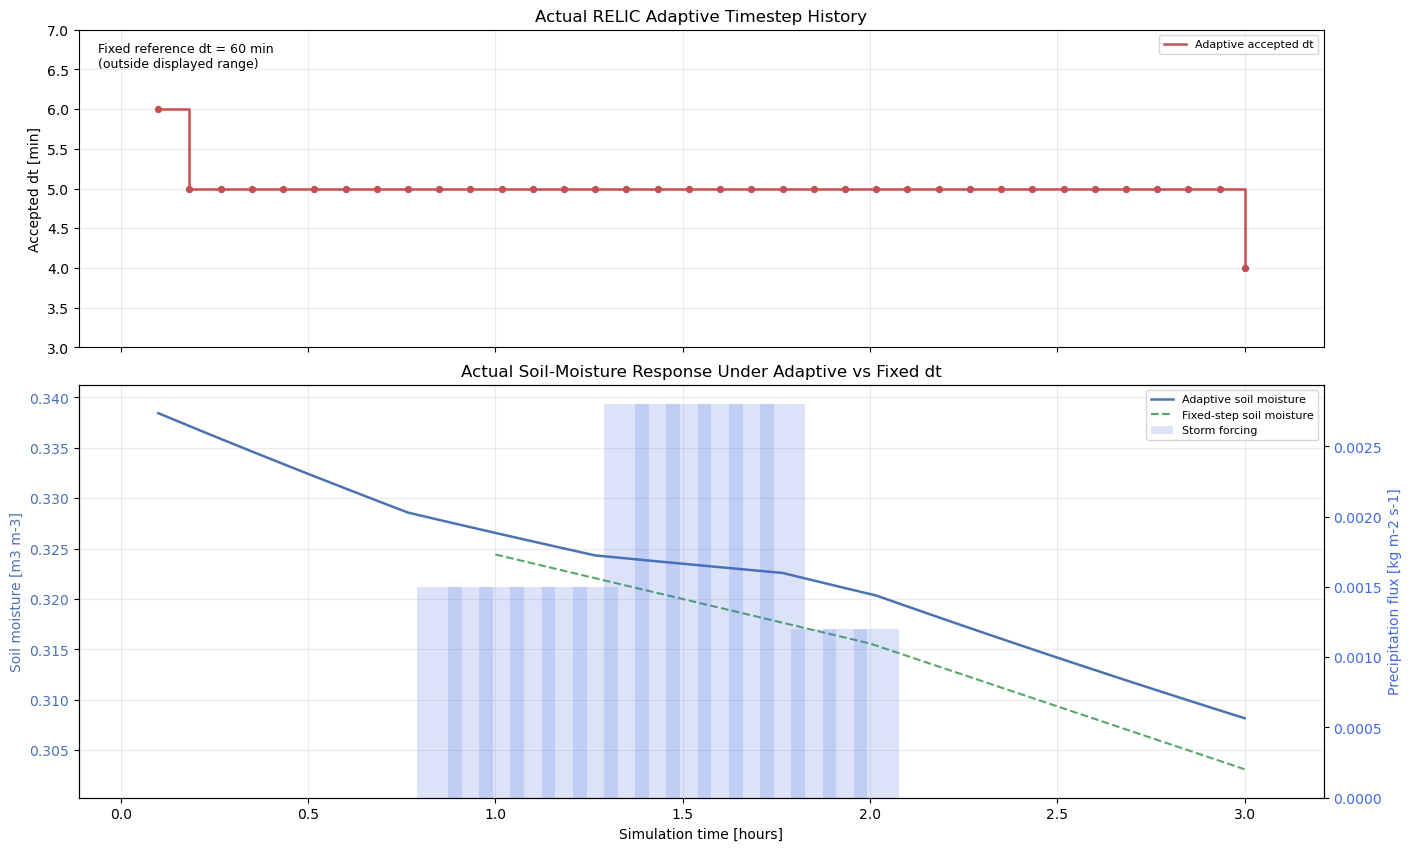

[OK] NB12 adaptive trajectory figure is based on actual simulator outputs and shows the accepted dt sequence explicitly.


In [7]:
from IPython.display import display
# References:
# - RELICSimulator.step() with adaptive_dt_enabled true/false
# - BucketSoilMoisture and PenmanMonteithET actual fast-process sequence
# Mathematical expression:
# - t_{n+1} = t_n + dt_eff,n
# - dt_eff,n is the accepted dt returned by the simulator after any adaptive retry
# Parameter meanings:
# - adaptive_records, fixed_records: actual RELIC trajectories prepared in cell 14

adaptive_time = [record['time_hours'] for record in adaptive_records]
adaptive_dt_minutes = [record['effective_dt_seconds'] / 60.0 for record in adaptive_records]
adaptive_theta = [record['soil_moisture'] for record in adaptive_records]
adaptive_precip = [record['precipitation_flux'] for record in adaptive_records]

fixed_time = [record['time_hours'] for record in fixed_records]
fixed_theta = [record['soil_moisture'] for record in fixed_records]

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 8.4),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={'height_ratios': [1.0, 1.3]},
)

dt_min = min(adaptive_dt_minutes)
dt_max = max(adaptive_dt_minutes)
dt_pad = max(1.0, 0.08 * max(dt_max - dt_min, 1.0))
axes[0].step(adaptive_time, adaptive_dt_minutes, where='post', color='#C44E52', linewidth=1.8, label='Adaptive accepted dt')
axes[0].scatter(adaptive_time, adaptive_dt_minutes, color='#C44E52', s=18, zorder=3)
axes[0].text(0.015, 0.96, 'Fixed reference dt = 60 min\n(outside displayed range)',
             transform=axes[0].transAxes, ha='left', va='top', fontsize=9)
axes[0].set_ylim(max(0.0, dt_min - dt_pad), dt_max + dt_pad)
axes[0].set_ylabel('Accepted dt [min]')
axes[0].set_title('Actual RELIC Adaptive Timestep History')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].grid(True, alpha=0.25)

theta_ax = axes[1]
forcing_ax = theta_ax.twinx()
theta_ax.plot(adaptive_time, adaptive_theta, color='#4C72B0', linewidth=1.8, label='Adaptive soil moisture')
theta_ax.plot(fixed_time, fixed_theta, color='#55A868', linewidth=1.5, linestyle='--', label='Fixed-step soil moisture')
forcing_ax.bar(adaptive_time, adaptive_precip, width=0.12, color='royalblue', alpha=0.18, label='Storm forcing')
theta_min = min(min(adaptive_theta), min(fixed_theta))
theta_max = max(max(adaptive_theta), max(fixed_theta))
theta_pad = max(0.0015, 0.08 * max(theta_max - theta_min, 1.0e-4))
theta_ax.set_ylim(theta_min - theta_pad, theta_max + theta_pad)
theta_ax.set_xlabel('Simulation time [hours]')
theta_ax.set_ylabel('Soil moisture [m3 m-3]', color='#4C72B0')
forcing_ax.set_ylabel('Precipitation flux [kg m-2 s-1]', color='royalblue')
theta_ax.tick_params(axis='y', labelcolor='#4C72B0')
forcing_ax.tick_params(axis='y', labelcolor='royalblue')
theta_ax.set_title('Actual Soil-Moisture Response Under Adaptive vs Fixed dt')
theta_ax.grid(True, alpha=0.25)
theta_handles, theta_labels = theta_ax.get_legend_handles_labels()
forcing_handles, forcing_labels = forcing_ax.get_legend_handles_labels()
theta_ax.legend(theta_handles + forcing_handles, theta_labels + forcing_labels, fontsize=8, loc='upper right')

display(plt.gcf())
plt.close(plt.gcf())
print('[OK] NB12 adaptive trajectory figure is based on actual simulator outputs and shows the accepted dt sequence explicitly.')

## RELIC Execution Groups and Operator Splitting

In production RELIC, operator splitting is implemented via
**execution groups** in the simulator:

- `relic.core.simulator.execution_group` executes one group order and commits it once (`_execute_group`)
- `relic.core.simulator.execution_loop` applies the configured Lie or Strang composition to the fast group only; medium and slow groups run sequentially afterwards when triggered
- `RELICSimulator.register_functor()` assigns each Functor by one priority chain: the `execution_group` argument, the Functor attribute, `characteristic_time_days`, `temporal_scale` metadata, a `process_groups` entry (used only when none of the rules before it applies; an entry that contradicts the attribute, characteristic-time or temporal-scale rule raises `ValueError`), and `fast` only when nothing is declared; an invalid declaration raises `ValueError`

The operators $f_A$ and $f_B$ demonstrated above are both members of the fast group; the next
cell also traces one actual Strang step.

In [8]:
# References:
# - relic/core/simulator/main.py
# - relic/core/simulator/execution_loop.py
# Mathematical expression:
# - fast group executes every step; medium and slow depend on interval and event triggers
# Parameter meanings:
# - _order_fast: actual fast-group execution order resolved by the simulator
# - _splitting_mode: configured operator-splitting mode for the fast group
# - _adaptive_next_dt: next proposed dt after adaptive control
# - strang_trace: (order, dt, start_time) of every fast sub-execution in one Strang step
# - strang_commits: StateManager.apply_updates calls, recorded as the sub-execution count so far
# - splitting_report: effective order q = min(2, min_i p_i) from the declared sub_flow_accuracy

introspection_simulator = build_hydrology_simulator(
    splitting_mode='lie',
    adaptive_enabled=True,
    time_step=3600.0,
)
summary = introspection_simulator.get_functor_summary()

print('=== Actual Simulator Introspection ===')
print(f"Fast order           : {introspection_simulator._order_fast}")
print(f"Medium order         : {introspection_simulator._order_medium}")
print(f"Slow order           : {introspection_simulator._order_slow}")
print(f"Configured splitting : {introspection_simulator._splitting_mode}")
print(f"Adaptive enabled     : {introspection_simulator._adaptive_dt_enabled}")
print(f"Adaptive dt bounds   : [{introspection_simulator._adaptive_dt_min:.1f}, {introspection_simulator._adaptive_dt_max:.1f}] s")
print('Registered functors:')
for functor_name, metadata in summary.items():
    print(f"  {functor_name:22s} inputs={metadata['input_variables']} outputs={metadata['output_variables']}")

# Strang call trace: wrap the simulator's own group executor and StateManager commit to record
# every fast sub-execution of one actual step (the runtime code path is unchanged).
strang_simulator = build_hydrology_simulator(splitting_mode='strang', adaptive_enabled=False, time_step=1800.0)
strang_trace = []
strang_commits = []
runtime_execute_group = strang_simulator._execute_group
runtime_apply_updates = strang_simulator.state_manager.apply_updates


def traced_execute_group(group_order, dt, *args, **kwargs):
    # start_time is keyword-only in _execute_group(group_order, dt, *, start_time)
    strang_trace.append((list(group_order), float(dt), float(kwargs['start_time'])))
    return runtime_execute_group(group_order, dt, *args, **kwargs)


def traced_apply_updates(*args, **kwargs):
    strang_commits.append(len(strang_trace))
    return runtime_apply_updates(*args, **kwargs)


strang_simulator._execute_group = traced_execute_group
strang_simulator.state_manager.apply_updates = traced_apply_updates
strang_start_time = float(strang_simulator.current_time)
strang_simulator.step()
print('Strang sub-executions in one step (order, dt [s], start_time [s]):')
for group_order, dt_value, time_value in strang_trace:
    print(f"  {group_order} dt={dt_value:.1f} start_time={time_value:.1f}")
print(f"StateManager commits during the step: {len(strang_commits)} (after sub-executions {strang_commits})")
assert len(strang_trace) == 2 * len(strang_simulator._order_fast) - 1
assert [dt_value for _, dt_value, _ in strang_trace] == [900.0, 1800.0, 900.0]
assert [time_value for _, _, time_value in strang_trace] == [
    strang_start_time, strang_start_time, strang_start_time + 900.0
]
assert strang_commits == [1, 2, 3]
splitting_report = strang_simulator.get_splitting_order_report()
print(f"Splitting order report: mode={splitting_report['splitting_mode']}, "
      f"sub_flow_accuracy={splitting_report['sub_flow_accuracy']}, "
      f"effective_order={splitting_report['effective_order']}")
print('[OK] NB12 now introspects actual simulator state instead of listing module names abstractly.')

Strang splitting is configured but its effective order is unverified: fast Functors ['penman_monteith_et'] declare no sub_flow_accuracy, so the second-order claim of the palindromic composition is not established.


=== Actual Simulator Introspection ===
Fast order           : ['penman_monteith_et', 'bucket_soil_moisture']
Medium order         : []
Slow order           : []
Configured splitting : lie
Adaptive enabled     : True
Adaptive dt bounds   : [300.0, 3600.0] s
Registered functors:
  penman_monteith_et     inputs=['net_radiation', 'air_temperature', 'wind_speed', 'atmospheric_pressure', 'relative_humidity', 'vapor_pressure_deficit', 'aerodynamic_resistance', 'precipitation_flux', 'canopy_storage', 'leaf_area_index', 'surface_resistance', 'canopy_conductance'] outputs=['evapotranspiration_flux', 'latent_heat_flux', 'diagnostics.vapor_pressure_deficit', 'diagnostics.aerodynamic_conductance', 'diagnostics.canopy_conductance', 'canopy_storage', 'diagnostics.evapotranspiration']
  bucket_soil_moisture   inputs=['soil_moisture', 'precipitation_flux', 'evapotranspiration_flux'] outputs=['soil_moisture', 'surface_runoff_flux', 'drainage_flux', 'diagnostics.soil_moisture_bucket']
Strang sub-executio

## Part 5: Demo Step-Size Formula and the Runtime Controller

The textbook I-controller form used for comparison in this part is:

$$\Delta t_{n+1} = \Delta t_n \cdot \min\left(\alpha_{\max}, \max\left(\alpha_{\min},\;
  \frac{0.9}{\mathcal{E}_n^{1/p}}\right)\right)$$

where:
- $\mathcal{E}_n$ would be a Richardson-type error norm built from the full-step versus
  two-half-step mismatch; the next cell computes only that mismatch from two real RELIC runs as
  a diagnostic, and it does not feed the controller.
- $p$ = method order used by this demo only
- $\alpha_{\min}, \alpha_{\max}$ = demo bounds (runtime: 0.1 and 5)

The runtime controller does not use this formula: it uses
$\Delta t_{n+1}=\Delta t_n\min(5,\max(0.1,0.9/\sqrt{\mathcal E_n}))$ with a fixed exponent $1/2$ for
both Lie and Strang, where $\mathcal E_n$ is the RMS of the tolerance-scaled changes applied by
the fast group (`_compute_error_norm()`; the committed value minus the pre-step value, with rates integrated once); it is a control heuristic. A rejected attempt longer than $\Delta t_{\min}$ is
retried once over a shorter interval and accepted without a second check; an attempt at or below
$\Delta t_{\min}$ is accepted with a WARNING.

### Accept/Reject Logic (runtime)

$$\text{if } \mathcal{E}_n \leq 1: \quad \text{ACCEPT step; next } \Delta t \text{ from the formula (}2\Delta t\text{ if }\mathcal{E}_n=0\text{), clipped to } [\Delta t_{\min}, \Delta t_{\max}]$$
$$\text{if } \mathcal{E}_n > 1 \text{ and } \Delta t > \Delta t_{\min}: \quad \text{ROLL BACK, retry once with } \max(\Delta t\max(0.1, 0.9/\sqrt{\mathcal{E}_n}), \Delta t_{\min}) < \Delta t \text{, accept without a second check}$$
$$\text{if } \mathcal{E}_n > 1 \text{ and } \Delta t \le \Delta t_{\min}: \quad \text{ACCEPT without rollback (WARNING); next } \Delta t \text{ as for an accepted step}$$

This heuristic is the step-size layer of the constraint chain; it is not a stability or CFL guarantee.

> **Reference** (textbook controller): Hairer, Norsett & Wanner (1993), *Solving ODE I*, Sec.II.4


In [9]:
# References:
# - Full-step versus two-half-step comparison (a notebook diagnostic; the RELIC adaptive
#   retry uses _compute_error_norm() on the changes applied by the fast group, not this comparison)
# Mathematical expression:
# - epsilon_local(v) = |v_half+half - v_full|
# Parameter meanings:
# - full step: one actual RELIC fast-group step of length dt
# - half+half: two actual RELIC fast-group steps of length dt/2
# - richardson_metrics: absolute local mismatch per variable

richardson_state = make_hydrology_state(
    soil_moisture=0.32,
    precipitation_flux=0.0018,
    evapotranspiration_flux=0.0,
    net_radiation=260.0,
    air_temperature=295.15,
    relative_humidity=0.65,
    vapor_pressure_deficit=1500.0,
    surface_resistance=120.0,
)
richardson_dt = 1800.0
richardson_metrics = richardson_comparison(richardson_state, richardson_dt)

print('=== Actual Richardson Comparison ===')
print(f"Base dt [s] : {richardson_dt:.1f}")
for variable_name, difference in richardson_metrics.items():
    print(f"  {variable_name:24s} |half-half - full| = {difference:.6e}")
print('[OK] NB12 Richardson diagnostics are now derived from actual RELIC fast-group integrations.')

=== Actual Richardson Comparison ===
Base dt [s] : 1800.0
  soil_moisture            |half-half - full| = 1.487136e-04
  evapotranspiration_flux  |half-half - full| = 0.000000e+00
  drainage_flux            |half-half - full| = 1.117422e-04
[OK] NB12 Richardson diagnostics are now derived from actual RELIC fast-group integrations.


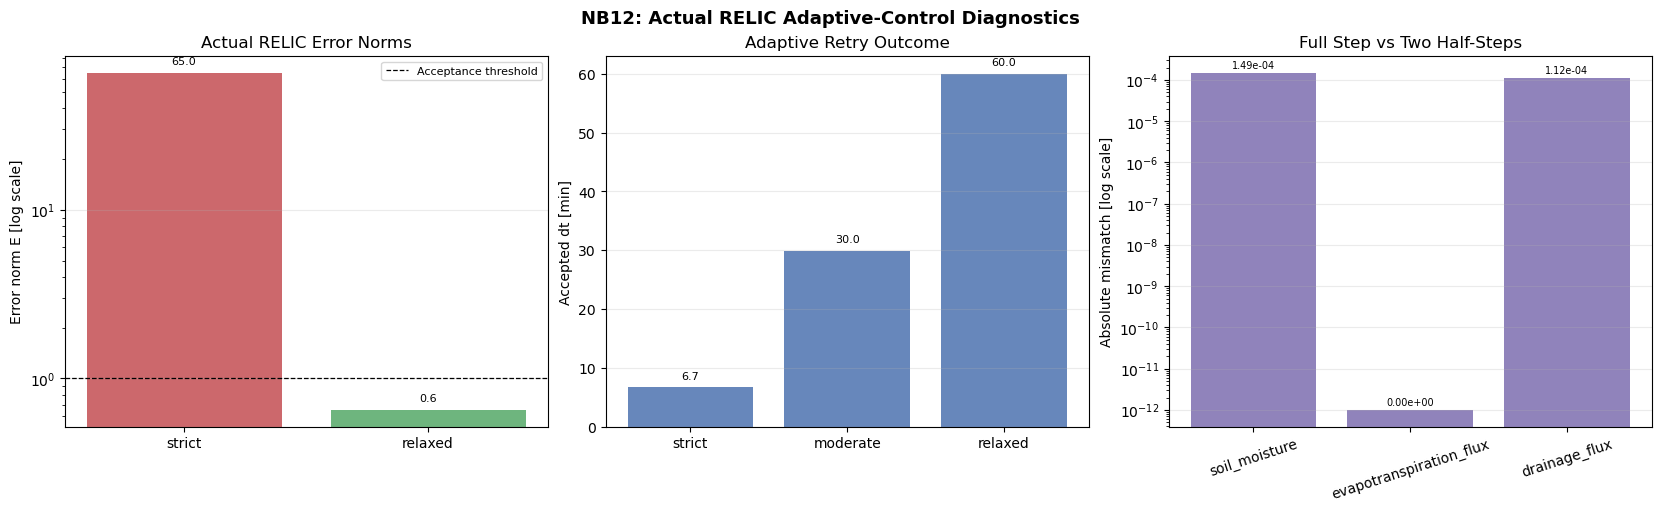

[OK] NB12 diagnostic figure combines actual simulator error norms, adaptive retry outcomes, and Richardson mismatches.


In [10]:
from IPython.display import display
# References:
# - RELIC adaptive retry and Richardson comparison diagnostics
# Mathematical expression:
# - accepted_dt = step result after retry logic
# - epsilon_local(v) = |v_half+half - v_full|
# Parameter meanings:
# - error_norm_summary, adaptive_sweep_summary, richardson_metrics: actual RELIC diagnostics from cells 11, 12, and 21

fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.0), constrained_layout=True)

error_names = list(error_norm_summary.keys())
error_values = [error_norm_summary[name] for name in error_names]
error_plot_values = [max(value, 1.0e-8) for value in error_values]
axes[0].bar(error_names, error_plot_values, color=['#C44E52', '#55A868'], alpha=0.85)
axes[0].axhline(1.0, color='black', linewidth=0.9, linestyle='--', label='Acceptance threshold')
axes[0].set_yscale('log')
axes[0].set_ylabel('Error norm E [log scale]')
axes[0].set_title('Actual RELIC Error Norms')
axes[0].grid(True, axis='y', alpha=0.25)
axes[0].legend(fontsize=8, loc='upper right')
for index, (value, plot_value) in enumerate(zip(error_values, error_plot_values)):
    axes[0].text(index, plot_value * 1.10, f'{value:.1f}', ha='center', va='bottom', fontsize=8)

sweep_names = list(adaptive_sweep_summary.keys())
accepted_dt = [adaptive_sweep_summary[name]['effective_dt_seconds'] / 60.0 for name in sweep_names]
axes[1].bar(sweep_names, accepted_dt, color='#4C72B0', alpha=0.85)
axes[1].set_ylabel('Accepted dt [min]')
axes[1].set_title('Adaptive Retry Outcome')
axes[1].grid(True, axis='y', alpha=0.25)
for index, value in enumerate(accepted_dt):
    axes[1].text(index, value + 1.0, f'{value:.1f}', ha='center', va='bottom', fontsize=8)

richardson_names = list(richardson_metrics.keys())
richardson_values = [richardson_metrics[name] for name in richardson_names]
richardson_plot_values = [max(value, 1.0e-12) for value in richardson_values]
axes[2].bar(richardson_names, richardson_plot_values, color='#8172B2', alpha=0.88)
axes[2].set_yscale('log')
axes[2].set_ylabel('Absolute mismatch [log scale]')
axes[2].set_title('Full Step vs Two Half-Steps')
axes[2].tick_params(axis='x', rotation=18)
axes[2].grid(True, axis='y', alpha=0.25)
for index, (value, plot_value) in enumerate(zip(richardson_values, richardson_plot_values)):
    axes[2].text(index, plot_value * 1.18, f'{value:.2e}', ha='center', va='bottom', fontsize=7)

plt.suptitle('NB12: Actual RELIC Adaptive-Control Diagnostics', fontsize=13, fontweight='bold')
display(plt.gcf())
plt.close(plt.gcf())
print('[OK] NB12 diagnostic figure combines actual simulator error norms, adaptive retry outcomes, and Richardson mismatches.')

In [11]:
# References:
# - RELICSimulator.register_event_trigger()
# - PenmanMonteithET and BucketSoilMoisture in the governed simulator lifecycle
# Mathematical expression:
# - trigger_medium(state, t) = 1 if precipitation_flux > threshold else 0
# Parameter meanings:
# - precipitation_flux: externally supplied forcing [kg m-2 s-1]
# - medium_interval_seconds: nominal interval for the medium group [s]
# - soil_moisture: BucketSoilMoisture state updated only if the medium group executes
# Units: forcing and drainage [kg m-2 s-1], soil moisture [m3 m-3], time [s].
# Domain/constraints: the trigger threshold is positive and the event forcing is finite.
# Sign convention: precipitation is positive into the soil-water control volume.

event_log_stream = io.StringIO()
event_handler = logging.StreamHandler(event_log_stream)
event_logger = logging.getLogger('relic.core.simulator.execution_loop')
event_logger.setLevel(logging.WARNING)
event_logger.addHandler(event_handler)

event_simulator = build_precipitation_event_simulator()
event_state_before = event_simulator._get_current_state()
event_simulator.step()

event_logger.removeHandler(event_handler)
event_state = event_simulator._get_current_state()

event_summary = {
    'precipitation_flux': tensor_scalar(event_state['precipitation_flux']),
    'soil_moisture_before': tensor_scalar(event_state_before['soil_moisture']),
    'soil_moisture_after': tensor_scalar(event_state['soil_moisture']),
    'drainage_flux': tensor_scalar(event_state['drainage_flux']),
}

print('=== Actual Event-Triggered Execution ===')
print(f"Fast group   : {event_simulator._order_fast}")
print(f"Medium group : {event_simulator._order_medium}")
print(f"Current time : {event_simulator.current_time:.1f} s")
print(f"Precipitation: {event_summary['precipitation_flux']:.6e} kg m-2 s-1")
print(f"Soil moisture: {event_summary['soil_moisture_before']:.6f} -> {event_summary['soil_moisture_after']:.6f}")
print(f"Drainage flux: {event_summary['drainage_flux']:.6e} kg m-2 s-1")
assert event_summary['soil_moisture_after'] != event_summary['soil_moisture_before']
print('[OK] NB12 event-trigger example uses external precipitation and the governed medium-group BucketSoilMoisture consumer.')

=== Actual Event-Triggered Execution ===
Fast group   : ['penman_monteith_et']
Medium group : ['bucket_soil_moisture']
Current time : 3600.0 s
Precipitation: 1.500000e-03 kg m-2 s-1
Soil moisture: 0.340000 -> 0.329065
Drainage flux: 4.519423e-03 kg m-2 s-1
[OK] NB12 event-trigger example uses external precipitation and the governed medium-group BucketSoilMoisture consumer.


## Adaptive Control in the Constraint Chain

The adaptive timestep is the step-size layer of the three-layer chain:

| Layer | What it ensures | RELIC mechanism |
|---|---|---|
| **Structure** ($\sigma$) | Topology consistency | `get_topology_signature()` (NB14) |
| **Budget** ($r_{\text{clip}}$) | Flux balance | `clip_loss` diagnostic (NB11) |
| **Step size** ($\mathcal{E}_n$ heuristic) | Returned-update magnitude kept near tolerance (no stability or CFL guarantee) | I-controller-style adaptive $\Delta t$ |

### Multi-Rate Temporal Execution Group $\gamma$

$$\gamma : \mathcal{T} \to \{\text{fast}, \text{medium}, \text{slow}\}$$

| Execution Group | Characteristic-time class (not an execution interval) | Example Processes |
|---|---|---|
| **fast** | $\leq \tau_f$ (current configuration: 1 day) | Photosynthesis, Energy balance |
| **medium** | $\tau_f$ to $\tau_m$ (1-10 days) | Soil hydrology, Decomposition |
| **slow** | $> \tau_m$ (10 days) | Phenology, Land use change |

The class is one step of the assignment priority chain (the `execution_group` argument, the Functor
attribute, `characteristic_time_days`, `temporal_scale`, `process_groups`, and `fast` only when nothing
is declared; every declaration is validated, and a `process_groups` entry that contradicts the attribute,
characteristic-time or temporal-scale rule raises `ValueError`). The medium
group executes at `medium_interval_seconds` boundaries; the slow group at `slow_interval_seconds`
boundaries or, if that key is unset, at calendar-month boundaries of the configured calendar
(`noleap` or `360_day`).

Event triggers registered for the medium or slow group add an execution when they return True
or a nonzero int (the group then runs with $h_g=t_{\rm future}-t_{\rm last}$); False or 0 does not
start the group. Triggers do not change the classification. A trigger that raises, or that returns
a type other than bool or int (for example None, a float or a tensor), fails the step with a
RuntimeError that names the trigger and the group, and the step transaction is rolled back.


---
## Part 3: Advanced Multi-Rate Execution & Adaptive Control

> **Reference:** `docs/source/theory/spatiotemporal_scale_topology.md` Sec 5, 7
>
> These sections cover the cross-group lag warnings (sampling and hold), the runtime adaptive
> step-size rule, and order sensitivity.


### 3.1 Cross-Group Sampling and Hold Lag

In multi-rate execution a slower Functor may read a variable produced by a faster Functor; it
samples that value only when its own group executes (sampling lag). A faster Functor may read a
variable produced by a slower Functor; it holds the value committed when that producer last ran
(hold lag).

**Warning condition:** `_warn_cross_group_dependencies()` in `execution_loop.py` (run at every
provider-view publication, not per step) compares declared inputs and outputs across groups with
the ranks $\text{fast}=0,\ \text{medium}=1,\ \text{slow}=2$ and warns in both directions:

$$\text{rank}(\text{group}(\text{reader}(v))) > \text{rank}(\text{group}(\text{writer}(v))) \;\Rightarrow\; \text{"Cross-group sampling lag"}$$

$$\text{rank}(\text{group}(\text{reader}(v))) < \text{rank}(\text{group}(\text{writer}(v))) \;\Rightarrow\; \text{"Cross-group hold lag"}$$

A read is acknowledged (logged at DEBUG only) when the reader lists the writer in the `lagged`
part of its dependency declaration. With `strict_cross_group_dependencies=True` an
unacknowledged read raises `RuntimeError`, and the registration, retirement, or restore that
would publish the plan is rolled back.

**Mitigation:** with `resolve_cross_group_deps=True`, every slow consumer with an unacknowledged
sampling lag is moved into the medium group; it leaves the slow group and is integrated once per
medium interval. A Functor that was already a scheduled slow member moves only when
$t_{\text{last,slow}} = t_{\text{last,medium}}$; otherwise the publication raises `RuntimeError`.
Nothing moves into `fast`, and no staleness bound is computed.

In the example below `BucketSoilMoisture` lists `penman_monteith_et` in its `lagged` dependencies,
so its fast-to-medium read of `evapotranspiration_flux` is acknowledged: RELIC logs it at DEBUG
and emits no lag warning. The declaration does not change what the bucket reads; it reads the
value the state holds when the medium group runs.


In [12]:
# References:
# - RELIC execution_loop._warn_cross_group_dependencies()
# - PenmanMonteithET and BucketSoilMoisture metadata and dependency declarations
# Mathematical expression:
# - sampling-lag warning when consumer_group_rank > producer_group_rank for a shared variable;
#   hold-lag warning when consumer_group_rank < producer_group_rank; a read whose producer is
#   listed in the consumer's lagged dependencies is acknowledged and logged at DEBUG only
# Parameter meanings:
# - lag_warning_lines: WARNING records for unacknowledged cross-group reads (both kinds)
# - acknowledged_lines: DEBUG records for reads acknowledged by a lagged declaration
# - penman_monteith_et: fast producer of evapotranspiration_flux
# - bucket_soil_moisture: medium consumer of evapotranspiration_flux; it lists
#   penman_monteith_et in its lagged dependencies

log_stream = io.StringIO()
warning_handler = logging.StreamHandler(log_stream)
warning_handler.setFormatter(logging.Formatter('%(levelname)s %(message)s'))
warning_logger = logging.getLogger('relic.core.simulator.execution_loop')
previous_level = warning_logger.level
warning_logger.setLevel(logging.DEBUG)
warning_logger.addHandler(warning_handler)

warning_simulator = build_hydrology_simulator(bucket_execution_group='medium')
warning_simulator.state_manager.set_state(hydrology_forcing_at_hour(0.0), validate=False)
warning_simulator.step()

warning_logger.removeHandler(warning_handler)
warning_logger.setLevel(previous_level)
log_lines = log_stream.getvalue().splitlines()
lag_warning_lines = [
    line for line in log_lines if 'Cross-group sampling lag' in line or 'Cross-group hold lag' in line
]
acknowledged_lines = [line for line in log_lines if 'Cross-group read acknowledged' in line]
bucket_dependencies = warning_simulator.functors['bucket_soil_moisture'].get_dependencies()

print('=== Actual Cross-Group Read Governance ===')
print(f"Groups                         : fast={warning_simulator._order_fast} medium={warning_simulator._order_medium}")
print(f"bucket_soil_moisture lagged    : {bucket_dependencies['lagged']}")
print(f"Lag warnings captured          : {len(lag_warning_lines)}")
print(f"Acknowledged reads captured    : {len(acknowledged_lines)}")
for line in acknowledged_lines:
    print(f'  {line}')
assert not lag_warning_lines, 'The fast-to-medium read is acknowledged by a lagged declaration; no warning is expected.'
assert any('evapotranspiration_flux' in line for line in acknowledged_lines)
print('[OK] NB12 cross-group read check uses the actual Penman-to-bucket fast/medium setup and its lagged declaration.')

=== Actual Cross-Group Read Governance ===
Groups                         : fast=['penman_monteith_et'] medium=['bucket_soil_moisture']
bucket_soil_moisture lagged    : ['penman_monteith_et', 'priestley_taylor_et']
Lag warnings captured          : 0
Acknowledged reads captured    : 1
  DEBUG Cross-group read acknowledged by a lagged declaration: 'bucket_soil_moisture' (group=medium) reads 'evapotranspiration_flux' from 'penman_monteith_et' (group=fast)
[OK] NB12 cross-group read check uses the actual Penman-to-bucket fast/medium setup and its lagged declaration.


### 3.2 Adaptive Time-Stepping: runtime rule

**Metric**: $\mathcal E$ = equal-weight RMS over monitored variables of the element-mean of
$(q/(\mathrm{atol}+\mathrm{rtol}|x|))^2$, with $q=x'-x$ the actual committed fast-group change, including rate integration
over the real interval, clipping and distributed reduction
and $x$ the pre-fast state (not Richardson, not embedded RK).

**Rule**:
1. If $\mathcal E>1$ and $\Delta t>\Delta t_{\min}$: restore the fast-group checkpoint, re-run once with $\max(\Delta t\max(0.1,0.9/\sqrt{\mathcal E}),\Delta t_{\min})$, which is shorter than the attempt, and accept that result without a second check.
2. If $\mathcal E>1$ and $\Delta t\le\Delta t_{\min}$: accept the attempt without rollback and log a WARNING naming $\mathcal E$ and $\Delta t_{\min}$; the next $\Delta t$ follows rule 3.
3. If $\mathcal E\le1$ (or after rule 2): accept; next $\Delta t=\Delta t\min(5,\max(0.1,0.9/\sqrt{\mathcal E}))$ ($2\Delta t$ if $\mathcal E=0$), clipped to $[\Delta t_{\min},\Delta t_{\max}]$.
4. There is no repeated-rejection loop and no adaptive-step exception. The integrated interval is never longer than the attempt, so `run()` never passes `end_time`.
5. $\mathcal E$ exists only after the fast group has run. A Functor that rejects the attempted interval raises before that: `PenmanMonteithET` raises `ValueError` for an actual step longer than `hydrosphere.physical.soil_heat_flux_hourly_max_step`, `FunctorBase.__call__` re-raises it as `ExecutionError`, and the step transaction restores the state and the clock. Such an error is a failed step, not a rejected attempt, so the controller does not retry it.


In [13]:
# References:
# - RELIC execution_loop._execute_fast_with_adaptive_retry()
# - Allen et al. (1998), FAO-56, Eqs. 45-46, and PenmanMonteithET.forward() (step-length check)
# Mathematical expression:
# - dt_retry = max(dt * max(0.1, 0.9 / sqrt(E)), dt_min) < dt when E > 1 and dt > dt_min
#   (accepted without a second check); otherwise the attempt dt is accepted
# - PenmanMonteithET accepts an actual step only when dt <= dt_G_max
# Parameter meanings:
# - input_dt_seconds: user-requested dt passed into simulator.step()
# - accepted_dt_seconds: actual dt accepted after retry logic
# - probe_state: same physical state tested at multiple requested dt values
# - dt_G_max: hydrosphere.physical.soil_heat_flux_hourly_max_step, the longest step of the
#   FAO-56 hourly soil heat flux fractions (G = 0.1 Rn for Rn > 0, 0.5 Rn otherwise)
# Units: dt, dt_retry, dt_min, dt_G_max [s]; E dimensionless.
# Domain/constraints: the probe requests steps up to dt_G_max. A longer request raises in
#   PenmanMonteithET before E exists, so it is a failed step (rolled back), not a retry.
# Sign convention: time advances forward; all intervals are positive.

from relic.core.functor import ExecutionError
from relic.parameters import get_global_manager

hourly_max_step = float(
    get_global_manager().get('hydrosphere.physical.soil_heat_flux_hourly_max_step', required=True)
)
probe_state = make_hydrology_state(
    soil_moisture=0.39,
    precipitation_flux=0.0030,
    evapotranspiration_flux=0.0,
    net_radiation=320.0,
    air_temperature=299.15,
    relative_humidity=0.55,
    vapor_pressure_deficit=2200.0,
    surface_resistance=100.0,
    aerodynamic_resistance=45.0,
)
input_dt_seconds = [900.0, 1800.0, 2700.0, 3600.0]
assert max(input_dt_seconds) <= hourly_max_step
adaptive_dt_probe = []
for input_dt in input_dt_seconds:
    response = one_step_adaptive_response(probe_state, input_dt)
    adaptive_dt_probe.append({
        'input_dt_seconds': input_dt,
        'accepted_dt_seconds': response['effective_dt_seconds'],
        'soil_moisture': response['soil_moisture'],
    })

print(f'PenmanMonteithET step limit dt_G_max = {hourly_max_step:.1f} s')
print('=== Actual Adaptive dt Probe ===')
for row in adaptive_dt_probe:
    print(
        f"requested dt = {row['input_dt_seconds']:7.1f} s | accepted dt = {row['accepted_dt_seconds']:7.1f} s | "
        f"soil_moisture = {row['soil_moisture']:.6f}"
    )
# Documentation oracle (not a controller): recompute E for each requested dt with
# _compute_error_norm() and compare the accepted dt with the documented rule.
probe_dt_min = build_hydrology_simulator(adaptive_enabled=True, time_step=3600.0)._adaptive_dt_min
print('Oracle check against the documented retry rule:')
for row in adaptive_dt_probe:
    requested_dt = row['input_dt_seconds']
    error_norm_value = evaluate_error_norm(probe_state, requested_dt)
    if error_norm_value > 1.0 and requested_dt > probe_dt_min:
        rule_dt = max(requested_dt * max(0.1, 0.9 / math.sqrt(error_norm_value)), probe_dt_min)
    else:
        rule_dt = requested_dt
    assert abs(row['accepted_dt_seconds'] - rule_dt) <= 1.0e-6 * rule_dt
    print(f"requested dt = {requested_dt:7.1f} s | E = {error_norm_value:10.4f} | rule dt = {rule_dt:7.1f} s | accepted dt matches")

# A request longer than dt_G_max is not a rejected adaptive attempt: PenmanMonteithET raises
# ValueError inside the fast group, FunctorBase.__call__ re-raises it as ExecutionError, and
# the step transaction restores the state and the clock.
long_dt = 2.0 * hourly_max_step
long_simulator = build_hydrology_simulator(adaptive_enabled=True, time_step=3600.0, initial_state=probe_state)
theta_before = tensor_scalar(long_simulator._get_current_state()['soil_moisture'])
try:
    long_simulator.step(dt=long_dt)
except ExecutionError as exc:
    long_step_error = exc
else:
    raise AssertionError('A step longer than dt_G_max must fail in PenmanMonteithET.')
theta_after = tensor_scalar(long_simulator._get_current_state()['soil_moisture'])
assert long_simulator.current_time == 0.0 and theta_after == theta_before
print(f"requested dt = {long_dt:7.1f} s | {type(long_step_error).__name__} caused by {type(long_step_error.__cause__).__name__}:")
print(f"  {long_step_error.__cause__}")
print(f"  after the failed step: time = {long_simulator.current_time:.1f} s, soil_moisture unchanged = {theta_after == theta_before}")
print('[OK] NB12 probes actual simulator retry behavior across requested dt values up to the PenmanMonteithET step limit.')

PenmanMonteithET step limit dt_G_max = 3600.0 s
=== Actual Adaptive dt Probe ===
requested dt =   900.0 s | accepted dt =   300.0 s | soil_moisture = 0.388905
requested dt =  1800.0 s | accepted dt =   300.0 s | soil_moisture = 0.388905
requested dt =  2700.0 s | accepted dt =   326.4 s | soil_moisture = 0.388808
requested dt =  3600.0 s | accepted dt =   370.6 s | soil_moisture = 0.388644
Oracle check against the documented retry rule:
requested dt =   900.0 s | E =    17.2381 | rule dt =   300.0 s | accepted dt matches


requested dt =  1800.0 s | E =    35.7083 | rule dt =   300.0 s | accepted dt matches
requested dt =  2700.0 s | E =    55.4354 | rule dt =   326.4 s | accepted dt matches
requested dt =  3600.0 s | E =    76.4438 | rule dt =   370.6 s | accepted dt matches


requested dt =  7200.0 s | ExecutionError caused by ValueError:
  PenmanMonteithET step dt=7200.0 s exceeds 3600.0 s, the validity limit of the FAO-56 hourly soil heat flux fractions (Eqs. 45-46)
  after the failed step: time = 0.0 s, soil_moisture unchanged = True
[OK] NB12 probes actual simulator retry behavior across requested dt values up to the PenmanMonteithET step limit.


### 3.3 Operator Splitting Sensitivity

**Order sensitivity** (as computed by `compute_splitting_sensitivity()` and in the next cell): for each
sampled permutation $\sigma$ of one group order, run one sequential pass and compute
$S(v)=\mathrm{std}_\sigma(|v_\sigma|)/\mathrm{mean}_\sigma(|v_\sigma|)$, where $|v_\sigma|$ is the element
mean of $|v|$ after that pass. RELIC reports these values; it does not flag variables or trigger
sub-stepping automatically. The next cell scans the raw difference between the two orders over $\Delta t$.


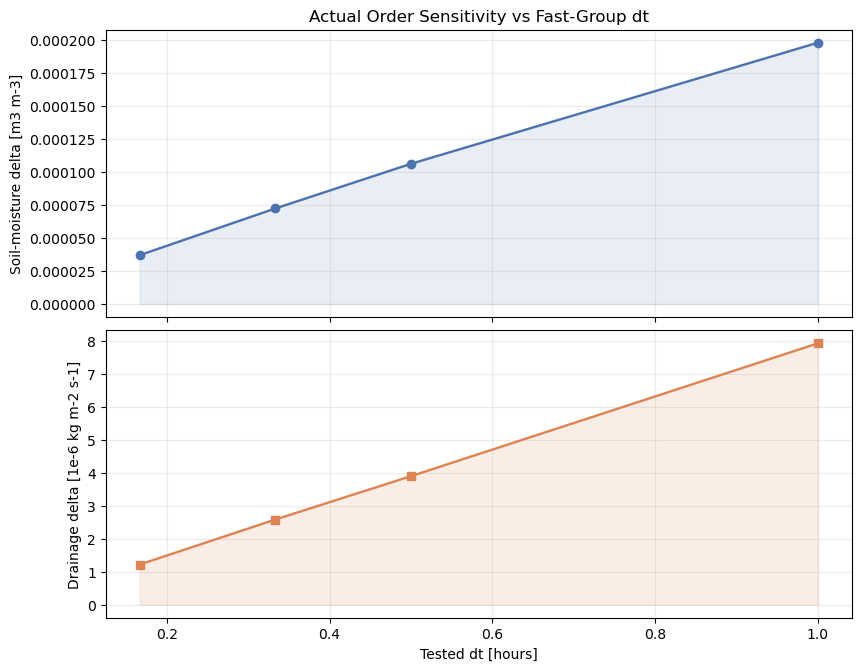

=== Actual Order-Sensitivity Scan ===
dt =   600.0 s | Delta soil_moisture = 3.698468e-05 | Delta drainage = 1.218868e-06
dt =  1200.0 s | Delta soil_moisture = 7.233024e-05 | Delta drainage = 2.584420e-06
dt =  1800.0 s | Delta soil_moisture = 1.061261e-04 | Delta drainage = 3.900612e-06
dt =  3600.0 s | Delta soil_moisture = 1.977384e-04 | Delta drainage = 7.932307e-06
[OK] NB12 now quantifies order sensitivity by scanning actual simulator permutations over dt.


In [14]:
from IPython.display import display
# References:
# - RELIC execution_loop.compute_splitting_sensitivity()
# - McLachlan and Quispel (2002), Acta Numerica.
# Mathematical expression:
# - Delta_v(dt) = |result_A->B(v) - result_B->A(v)|
# Parameter meanings:
# - dt_scan_seconds: tested fast-group dt values [s]
# - soil_moisture_delta: raw permutation difference in final soil moisture
# - drainage_delta: raw permutation difference in final drainage flux

dt_scan_seconds = [600.0, 1200.0, 1800.0, 3600.0]
permutation_delta_summary = []
for dt_value in dt_scan_seconds:
    simulator = build_hydrology_simulator(
        adaptive_enabled=False,
        time_step=dt_value,
        initial_state=split_state,
    )
    result = compute_splitting_sensitivity(
        simulator=simulator,
        state=simulator._get_current_state(),
        dt=dt_value,
        group_order=simulator._order_fast,
        n_permutations=2,
    )
    row_a, row_b = result['heatmap_data']
    permutation_delta_summary.append({
        'dt_seconds': dt_value,
        'soil_moisture_delta': abs(float(row_a['soil_moisture']) - float(row_b['soil_moisture'])),
        'drainage_delta': abs(float(row_a['drainage_flux']) - float(row_b['drainage_flux'])),
    })

dt_hours = [row['dt_seconds'] / 3600.0 for row in permutation_delta_summary]
soil_delta = [row['soil_moisture_delta'] for row in permutation_delta_summary]
drainage_delta_micro = [row['drainage_delta'] * 1.0e6 for row in permutation_delta_summary]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 6.6), sharex=True, constrained_layout=True)
axes[0].plot(dt_hours, soil_delta, marker='o', linewidth=1.7, color='#4C72B0')
axes[0].fill_between(dt_hours, [0.0] * len(dt_hours), soil_delta, color='#4C72B0', alpha=0.12)
axes[0].set_ylabel('Soil-moisture delta [m3 m-3]')
axes[0].set_title('Actual Order Sensitivity vs Fast-Group dt')
axes[0].grid(True, alpha=0.25)

axes[1].plot(dt_hours, drainage_delta_micro, marker='s', linewidth=1.7, color='#DD8452')
axes[1].fill_between(dt_hours, [0.0] * len(dt_hours), drainage_delta_micro, color='#DD8452', alpha=0.14)
axes[1].set_xlabel('Tested dt [hours]')
axes[1].set_ylabel('Drainage delta [1e-6 kg m-2 s-1]')
axes[1].grid(True, alpha=0.25)

display(plt.gcf())
plt.close(plt.gcf())

print('=== Actual Order-Sensitivity Scan ===')
for row in permutation_delta_summary:
    print(
        f"dt = {row['dt_seconds']:7.1f} s | Delta soil_moisture = {row['soil_moisture_delta']:.6e} | "
        f"Delta drainage = {row['drainage_delta']:.6e}"
    )
print('[OK] NB12 now quantifies order sensitivity by scanning actual simulator permutations over dt.')

---
## Numerical Time Integration Methods

> **Reference:** `docs/source/theory/numerical_time_integration.md`

RELIC supports multiple time integration strategies.


### Forward Euler (Explicit)

$$\mathbf{x}_{n+1} = \mathbf{x}_n + \Delta t \cdot f(\mathbf{x}_n, t_n)$$

- **Order:** 1st
- **Stability:** Conditionally stable ($\Delta t < \Delta t_{\text{crit}}$)
- **Usage:** what an individual Functor may use inside `forward`; the simulator itself selects no
  integrator (a FLUX payload is converted once to $q\,\Delta t$ over the group interval before the
  StateManager commit)

### Runge-Kutta 4 (RK4)

$$\mathbf{x}_{n+1} = \mathbf{x}_n + \frac{\Delta t}{6}(k_1 + 2k_2 + 2k_3 + k_4)$$

### Implicit Methods (for stiff systems)

**Backward Euler:**

$$\mathbf{x}_{n+1} = \mathbf{x}_n + \Delta t \cdot f(\mathbf{x}_{n+1}, t_{n+1})$$

Requires solving nonlinear system at each step.


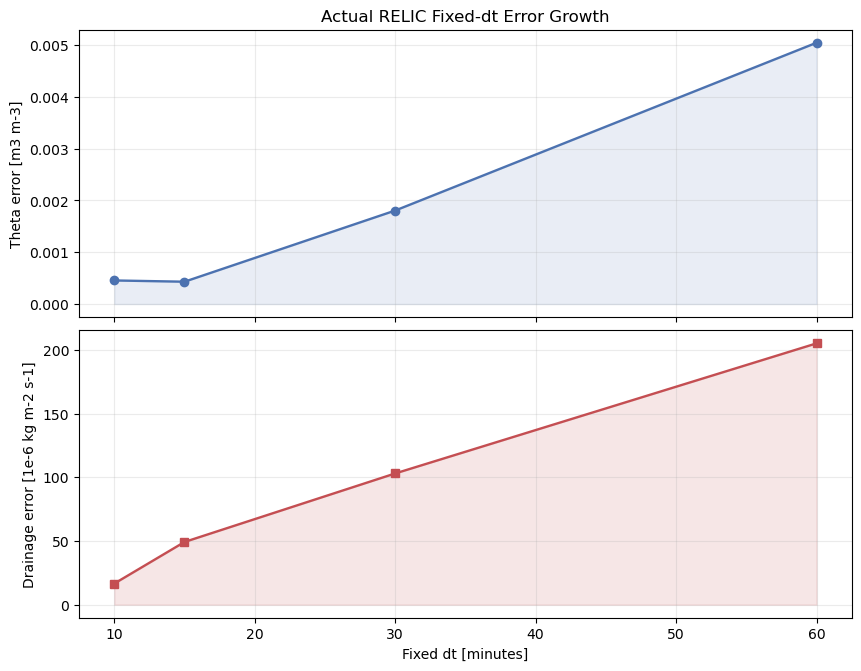

=== Actual Fixed-dt Comparison ===
Reference dt = 300 s
dt =   600.0 s | theta error = 4.554391e-04 | drainage error = 1.654495e-05
dt =   900.0 s | theta error = 4.311502e-04 | drainage error = 4.921365e-05
dt =  1800.0 s | theta error = 1.805991e-03 | drainage error = 1.030122e-04
dt =  3600.0 s | theta error = 5.047351e-03 | drainage error = 2.051278e-04
[OK] NB12 numerical time-integration comparison now uses actual RELIC fast-process runs rather than an external ODE toy problem.


In [15]:
from IPython.display import display
# References:
# - RELICSimulator.step() under fixed dt
# - BucketSoilMoisture and PenmanMonteithET actual time integration
# Mathematical expression:
# - error(dt) = |x_dt(T) - x_ref(T)|, where x_ref uses a finer actual RELIC timestep
# Parameter meanings:
# - reference_dt_seconds: fine RELIC timestep used as the numerical reference [s]
# - coarse_dt_seconds: tested fixed dt values [s]
# - final_theta_error: final soil-moisture mismatch against the fine-step reference

reference_dt_seconds = 300.0
coarse_dt_seconds = [600.0, 900.0, 1800.0, 3600.0]


def run_fixed_reference(dt_seconds: float) -> tuple[float, float]:
    simulator = build_hydrology_simulator(adaptive_enabled=False, time_step=dt_seconds)
    end_time_seconds = 3.0 * 3600.0
    while simulator.current_time < end_time_seconds - 1.0e-9:
        forcing = hydrology_forcing_at_hour(simulator.current_time / 3600.0)
        simulator.state_manager.set_state(forcing, validate=False)
        simulator.step(dt=min(dt_seconds, end_time_seconds - simulator.current_time))
    final_state = simulator._get_current_state()
    return tensor_scalar(final_state['soil_moisture']), tensor_scalar(final_state['drainage_flux'])


reference_theta, reference_drainage = run_fixed_reference(reference_dt_seconds)
integration_error_summary = []
for coarse_dt in coarse_dt_seconds:
    coarse_theta, coarse_drainage = run_fixed_reference(coarse_dt)
    integration_error_summary.append({
        'dt_seconds': coarse_dt,
        'theta_error': abs(coarse_theta - reference_theta),
        'drainage_error': abs(coarse_drainage - reference_drainage),
    })

dt_minutes = [row['dt_seconds'] / 60.0 for row in integration_error_summary]
theta_error = [row['theta_error'] for row in integration_error_summary]
drainage_error_micro = [row['drainage_error'] * 1.0e6 for row in integration_error_summary]

fig, axes = plt.subplots(2, 1, figsize=(8.5, 6.6), sharex=True, constrained_layout=True)
axes[0].plot(dt_minutes, theta_error, marker='o', linewidth=1.7, color='#4C72B0')
axes[0].fill_between(dt_minutes, [0.0] * len(dt_minutes), theta_error, color='#4C72B0', alpha=0.12)
axes[0].set_ylabel('Theta error [m3 m-3]')
axes[0].set_title('Actual RELIC Fixed-dt Error Growth')
axes[0].grid(True, alpha=0.25)

axes[1].plot(dt_minutes, drainage_error_micro, marker='s', linewidth=1.7, color='#C44E52')
axes[1].fill_between(dt_minutes, [0.0] * len(dt_minutes), drainage_error_micro, color='#C44E52', alpha=0.14)
axes[1].set_xlabel('Fixed dt [minutes]')
axes[1].set_ylabel('Drainage error [1e-6 kg m-2 s-1]')
axes[1].grid(True, alpha=0.25)
display(plt.gcf())
plt.close(plt.gcf())

print('=== Actual Fixed-dt Comparison ===')
print(f"Reference dt = {reference_dt_seconds:.0f} s")
for row in integration_error_summary:
    print(
        f"dt = {row['dt_seconds']:7.1f} s | theta error = {row['theta_error']:.6e} | "
        f"drainage error = {row['drainage_error']:.6e}"
    )
print('[OK] NB12 numerical time-integration comparison now uses actual RELIC fast-process runs rather than an external ODE toy problem.')

## Summary

| Concept | Method | Order | RELIC Setting |
|---------|--------|-------|---------------|
| Lie splitting | $\Phi_B \circ \Phi_A$ | $\mathcal{O}(\Delta t)$ | `splitting_mode: "lie"` |
| Strang splitting | $\Phi_{F_1}^{1/2} \circ \cdots \circ \Phi_{F_n} \circ \cdots \circ \Phi_{F_1}^{1/2}$ (palindrome over the fast order) | $\mathcal{O}(\Delta t^2)$ for exact smooth sub-flows (second half-steps start at $t+\Delta t/2$); in general $q=\min(2,\min_i p_i)$ from `sub_flow_accuracy`, "unverified" if undeclared | `splitting_mode: "strang"` |
| Error norm | $\mathcal{E} = \sqrt{\frac{1}{m}\sum(\delta_k/\text{tol}_k)^2}$, $\delta_k$ = change applied by the fast group | -- | `_compute_error_norm()` |
| I-controller | $\Delta t_{n+1} = \Delta t_n\min(5,\max(0.1,0.9/\sqrt{\mathcal{E}}))$, clipped to $[\Delta t_{\min},\Delta t_{\max}]$ | -- | `adaptive_dt_enabled: true` |

**Key insight:** Strang splitting can give second-order accuracy by symmetrizing the operator
sequence when the sub-flows are exact (the runtime passes the stage times $t$ and $t+\Delta t/2$), at the cost of $n-1$ extra
half-step evaluations ($2n-1$ sub-executions for $n$ fast Functors). The adaptive I-controller
steers the committed state-change magnitude toward tolerance (a control heuristic, not a local-error
estimate; at most one retry, accepted without a second check, and none for an attempt at or below
$\Delta t_{\min}$, so an accepted step may exceed tolerance).
It shrinks $\Delta t$ when $\mathcal E > 1$ and grows it only when $0.9/\sqrt{\mathcal E} > 1$, i.e.
$\mathcal E < 0.81$. In this example $\mathcal E$ measures the REPLACE changes of `soil_moisture` and
`drainage_flux`: cells 12, 14 and 29 report the fresh decisions, accepted intervals and retry
counts for the current code. These observed counts are not mathematical guarantees.